In [1]:
import pandas as pd

morpho_ind = pd.read_csv("from_dune/morpho_market_breakdown_individual.csv")
morpho_ind["wallet"] = morpho_ind["wallet"].str.lower().str.strip()

print(f"Rows: {len(morpho_ind):,}")
print(f"Distinct wallets: {morpho_ind['wallet'].nunique():,}")

Rows: 497
Distinct wallets: 437


In [2]:
EXCHANGE_RATES = { # todo take curr price from llama or other
    "syrupUSDC": 1.17,
    "sUSDe": 1.24,
    "sUSDS": 1.10,
}

morpho_ind["collateral_value_usd"] = morpho_ind["token_name"].map(EXCHANGE_RATES) * morpho_ind["collateral_balance"]

morpho_ind[["wallet", "token_name", "collateral_balance", "collateral_value_usd"]].head(10)

,wallet,token_name,collateral_balance,collateral_value_usd
0,0xd3e0d660d8fab05b34ccb7fe7681628d9a46c675,sUSDS,2.444235e+07,2.688659e+07
1,0xb907d8ffd28be854a75580adebc2af4063d0dd92,sUSDS,5.672004e+06,6.239204e+06
2,0x9fec8a63a6c6ef9eadddfbd79daba5918965794e,sUSDS,3.715357e+06,4.086893e+06
3,0x0cd7e1660d63a6aebda782a2eb7f2875716ac3e8,sUSDS,3.645471e+06,4.010018e+06
4,0xa1551154319a5458831f8e042692e01edadb893d,sUSDS,2.352175e+06,2.587392e+06
5,0x1d9c4116e5784036dbd15bced8aff88970b4a598,sUSDS,2.163692e+06,2.380062e+06
6,0xf07aded80f118a4fbcc2544db0f6310bd8ecd1eb,sUSDS,2.037202e+06,2.240923e+06
7,0x206777f4396817398ee61e7ac5e62af311e79836,sUSDS,1.914237e+06,2.105661e+06
8,0x81377b59e1c115ac63b21067b589266cdd5ffbd1,sUSDS,1.217500e+06,1.339250e+06
9,0xdf81987465681d0515058fe0a47a3bd174012730,sUSDS,1.162712e+06,1.278983e+06


In [3]:
# Operators = EOA + Gnosis Safe, applied to every whale figure below.
# Detect Safes among the Morpho collateral wallets the EOA-only whale flags miss
# (a Safe stores its singleton/masterCopy in storage slot 0), add them and any
# cache-missed EOAs as operators, and persist the combined flags for reuse.
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import requests

KNOWN_SAFE_SINGLETONS = {
    "0xb6029ea3b2c51d09a50b53ca8012feeb05bda35a",  # 1.0.0
    "0x34cfac646f301356faa8b21e94227e3583fe3f5f",  # 1.1.1
    "0xd9db270c1b5e3bd161e8c8503c55ceabee709552",  # 1.3.0
    "0x3e5c63644e683549055b9be8653de26e0b4cd36e",  # 1.3.0 L2
    "0x41675c099f32341bf84bfc5382af534df5c7461a",  # 1.4.1
    "0x29fcb43b46531bca003ddc8fcb67ffe91900c762",  # 1.4.1 L2
}
RPC_URLS = [
    "https://ethereum-rpc.publicnode.com",
    "https://eth.drpc.org",
    "https://1rpc.io/eth",
    "https://cloudflare-eth.com",
]
SAFE_CACHE_FILE = Path("safe_type_cache.json")
safe_cache = json.loads(SAFE_CACHE_FILE.read_text()) if SAFE_CACHE_FILE.exists() else {}
address_cache = json.loads(Path("address_type_cache.json").read_text()) if Path("address_type_cache.json").exists() else {}


def _rpc(method, params):
    payload = {"jsonrpc": "2.0", "id": 1, "method": method, "params": params}
    for url in RPC_URLS:
        try:
            r = requests.post(url, json=payload, timeout=20)
            r.raise_for_status()
            data = r.json()
            if data.get("result") is not None:
                return data["result"]
        except Exception:
            continue
    return None


def classify_address(addr):
    """eoa | safe | other_contract, cached."""
    if addr in safe_cache:
        return safe_cache[addr]
    is_contract = address_cache.get(addr)
    if is_contract is False:
        label = "eoa"
    else:
        raw = _rpc("eth_getStorageAt", [addr, "0x0", "latest"])
        singleton = ("0x" + raw[-40:]).lower() if raw and len(raw) >= 42 else None
        if singleton in KNOWN_SAFE_SINGLETONS:
            label = "safe"
        elif is_contract is True:
            label = "other_contract"
        else:
            code = _rpc("eth_getCode", [addr, "latest"])
            label = "other_contract" if (code and code != "0x") else "eoa"
    safe_cache[addr] = label
    return label


whale_flags_eoa = pd.read_csv("whale_flags.csv").rename(columns={"token": "token_name"})
whale_flags_eoa["wallet"] = whale_flags_eoa["wallet"].str.lower().str.strip()

unmatched = sorted(set(morpho_ind["wallet"]) - set(whale_flags_eoa["wallet"]))
todo = [w for w in unmatched if w not in safe_cache]
print(f"Morpho wallets not matched by EOA-only whale flags: {len(unmatched):,}")
print(f"Classifying {len(todo):,} via RPC (cached: {len(unmatched) - len(todo):,})...")
with ThreadPoolExecutor(max_workers=6) as ex:
    list(ex.map(classify_address, todo))
SAFE_CACHE_FILE.write_text(json.dumps(safe_cache))

labels = pd.Series({w: safe_cache.get(w, "eoa") for w in unmatched})
print("\nUnmatched Morpho holders by type:")
print(labels.value_counts())

# recovered operators get the same $1M total-YBS-exposure whale test as the panel
WHALE_THRESHOLD = 1_000_000
CSV_FILES = {
    "sUSDe": "from_dune/sUSDe_holders.csv",
    "sUSDS": "from_dune/sUSDS_holders.csv",
    "syrupUSDC": "from_dune/syrupUSDC_holders.csv",
}
exp_frames = []
for token, path in CSV_FILES.items():
    d = pd.read_csv(path)
    d["wallet"] = d["wallet"].str.lower().str.strip()
    d["total_YBS_exposure"] = pd.to_numeric(d["total_YBS_exposure"], errors="coerce").fillna(0.0).clip(lower=0.0)
    d["token_name"] = token
    exp_frames.append(d[["wallet", "token_name", "total_YBS_exposure"]])
exposure = pd.concat(exp_frames, ignore_index=True).groupby(["wallet", "token_name"])["total_YBS_exposure"].max()

safe_wallets = {w for w in unmatched if safe_cache.get(w) == "safe"}
eoa_unmatched = {w for w in unmatched if safe_cache.get(w) == "eoa"}
extra_rows = []
for w in sorted(safe_wallets | eoa_unmatched):
    for t in morpho_ind.loc[morpho_ind["wallet"] == w, "token_name"].unique():
        extra_rows.append({
            "wallet": w,
            "token_name": t,
            "is_whale": bool(exposure.get((w, t), 0.0) >= WHALE_THRESHOLD),
            "operator_type": "safe" if w in safe_wallets else "eoa",
        })
extra = pd.DataFrame(extra_rows, columns=["wallet", "token_name", "is_whale", "operator_type"])

flags_eoa = whale_flags_eoa.copy()
flags_eoa["operator_type"] = "eoa"
flags_op = pd.concat([flags_eoa, extra], ignore_index=True).drop_duplicates(["wallet", "token_name"], keep="first")
flags_op.to_csv("whale_flags_operator.csv", index=False)

n_safe_whales = int(extra.loc[extra["operator_type"] == "safe", "is_whale"].sum()) if not extra.empty else 0
print(f"\nSafes found: {len(safe_wallets):,}  |  Safe whales (>= $1M): {n_safe_whales}")
print(f"Extra EOA operators recovered: {len(eoa_unmatched):,}")
print("Saved combined operator flags -> whale_flags_operator.csv")


Morpho wallets not matched by EOA-only whale flags: 159
Classifying 155 via RPC (cached: 4)...



Unmatched Morpho holders by type:
other_contract    129
safe               25
eoa                 5
Name: count, dtype: int64



Safes found: 25  |  Safe whales (>= $1M): 3
Extra EOA operators recovered: 5
Saved combined operator flags -> whale_flags_operator.csv


## To which markets?

In [4]:
market_summary = morpho_ind.groupby(["token_name", "market_id", "loan_token_symbol"]).agg(
    num_wallets=("wallet", "nunique"),
    total_collateral_usd=("collateral_value_usd", "sum"),
    total_borrowed_usd=("borrowed_amount", "sum")
).reset_index()

market_summary = market_summary.sort_values(["token_name", "total_collateral_usd"], ascending=[True, False])
market_summary

,token_name,market_id,loan_token_symbol,num_wallets,total_collateral_usd,total_borrowed_usd
2,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,88,6.450778e+07,5.800025e+07
1,sUSDS,0x09cf702bb8b6fe8c6effb6021744e365f598b89bc28f...,AUSD,13,4.242433e+06,3.733727e+06
3,sUSDS,0xa5beccdffd156dfe8c0871f143648c512f0a34f37c8a...,PYUSD,2,2.357528e+04,2.071490e+04
4,sUSDS,0xb5b0ff0fccf16dff5bef6d2d001d60f5c4ab49df1020...,USDT,1,1.031992e+03,9.000000e+02
8,sUSDS,0xdcfd3558f75a13a3c430ee71df056b5570cbd628da91...,USDC,3,6.627094e+02,5.202001e+02
6,sUSDS,0xc032473959060d2c7bea5488718b6f3f15300873bb96...,USDtb,1,4.175138e+00,8.900000e-01
7,sUSDS,0xd78df901ce154470bc58e33d03cfe3af6b66e04d8e76...,tGBP,1,4.023935e+00,6.740741e-01
0,sUSDS,0x09597e3ede0ff531ac42b8c64e2a261984dc10954ae0...,RLUSD,1,4.021993e+00,9.100000e-01
5,sUSDS,0xbed21964cf290ab95fa458da6c1f302f2278aec5f897...,WETH,1,2.310000e+00,4.500000e-04
20,sUSDe,0x90ef0c5a0dc7c4de4ad4585002d44e9d411d212d2f62...,PYUSD,25,4.219705e+07,3.614457e+07


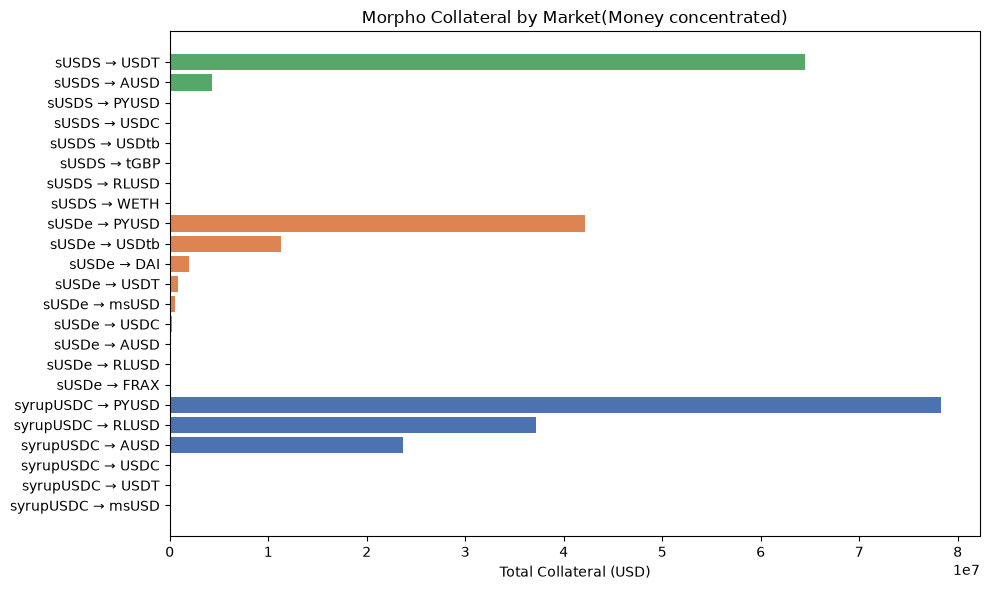

In [5]:
import matplotlib.pyplot as plt

# short label for each market so the chart is readable
market_summary["market_label"] = (
    market_summary["token_name"] + " → " + market_summary["loan_token_symbol"]
)

fig, ax = plt.subplots(figsize=(10, 6))

colors = {"syrupUSDC": "#4C72B0", "sUSDe": "#DD8452", "sUSDS": "#55A868"}
bar_colors = market_summary["token_name"].map(colors)

ax.barh(market_summary["market_label"], market_summary["total_collateral_usd"], color=bar_colors)
ax.set_xlabel("Total Collateral (USD)")
ax.set_title("Morpho Collateral by Market(Money concentrated)")
ax.invert_yaxis()  # largest at top

plt.tight_layout()
plt.show()

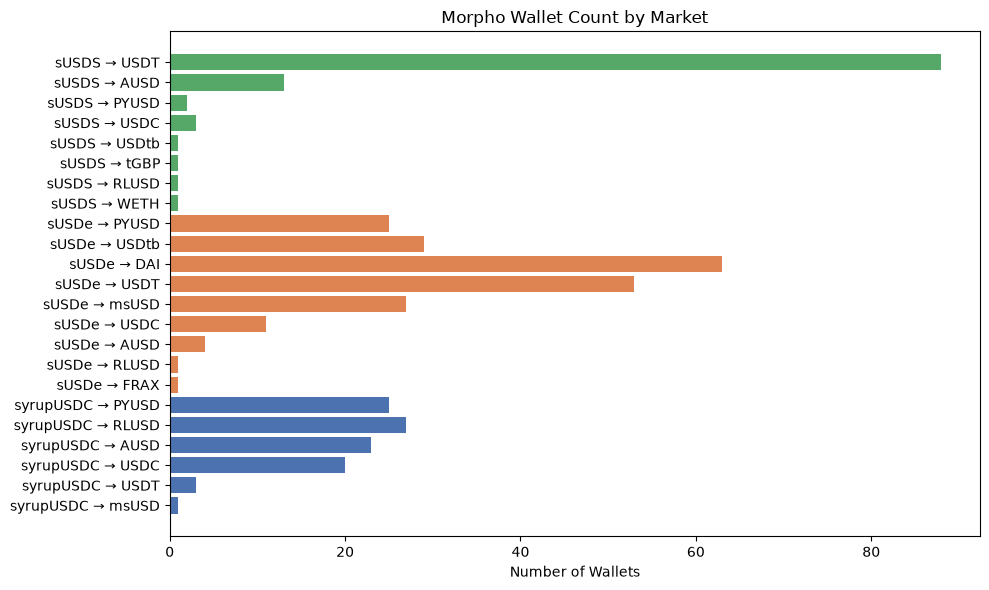

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(market_summary["market_label"], market_summary["num_wallets"], color=bar_colors)
ax.set_xlabel("Number of Wallets")
ax.set_title("Morpho Wallet Count by Market")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## What for; tied to what each wallet actually did in that market: borrowed a stablecoin against their collateral, borrowed something non-stable, or just parked collateral with no borrow at all

In [7]:
import pandas as pd

symbols = morpho_ind["loan_token_symbol"].unique()

stablecoins_df = pd.DataFrame({"symbol": symbols})
stablecoins_df.to_csv("stablecoins.csv", index=False)

stablecoins_df

,symbol
0,USDT
1,AUSD
2,PYUSD
3,USDC
4,USDtb
5,tGBP
6,RLUSD
7,WETH
8,DAI
9,msUSD


In [8]:
stablecoins_df = pd.read_csv("stablecoins.csv")
STABLES = set(stablecoins_df["symbol"]) - {"WETH"}

def tag_archetype(row):
    if row["borrowed_amount"] <= 0:
        return "collateral_only"
    if row["loan_token_symbol"] in STABLES:
        return "stablecoin_borrow"
    return "non_stable_borrow"

morpho_ind["market_archetype"] = morpho_ind.apply(tag_archetype, axis=1)
morpho_ind["market_archetype"].value_counts()

market_archetype
stablecoin_borrow    378
collateral_only      118
non_stable_borrow      1
Name: count, dtype: int64

## Morpho Market Breakdown - Which Markets & What For

**Which markets:** Across syrupUSDC, sUSDe, and sUSDS, Morpho collateral is heavily concentrated in one dominant market per token, rather than spread evenly:
- **syrupUSDC** - mostly the PYUSD market ($78.3M), with RLUSD ($37.2M) and AUSD ($23.7M) as secondary markets
- **sUSDe** - mostly the PYUSD market ($42.2M), with USDtb ($11.3M) as a secondary market
- **sUSDS** - mostly the USDT market ($64.5M), with AUSD ($4.2M) a distant second

Several other markets exist (USDC, DAI, tGBP, WETH, msUSD) but hold negligible collateral by comparison.

**What for (archetypes):** Of the 497 wallet-market positions analysed:

| Archetype | Count | % |
|---|---|---|
| Stablecoin borrow | 378 | 76% |
| Collateral only (no active borrow) | 118 | 24% |
| Non-stable borrow (WETH) | 1 | ~0% |

The dominant pattern (76%) is **posting YBS as collateral and borrowing a stablecoin against it**, consistent with a leveraged yield strategy. About a quarter of positions hold collateral with no active borrow, which may reflect closed/repaid loops rather than pure idle holding. Non-stablecoin borrowing is essentially absent (1 position, WETH).

## Q: What whales are doing?

In [9]:
whale_flags = pd.read_csv("whale_flags_operator.csv")
whale_flags["wallet"] = whale_flags["wallet"].str.lower().str.strip()

morpho_ind_whales = morpho_ind.merge(
    whale_flags[["wallet", "token_name", "is_whale"]], on=["wallet", "token_name"], how="left"
)
morpho_ind_whales["is_whale"] = morpho_ind_whales["is_whale"].fillna(False)

morpho_ind_whales["is_whale"].value_counts(dropna=False)


is_whale
False    450
True      47
Name: count, dtype: int64

In [10]:
archetype_by_whale = morpho_ind_whales.groupby(["is_whale", "market_archetype"]).size().unstack(fill_value=0)
archetype_by_whale_pct = archetype_by_whale.div(archetype_by_whale.sum(axis=1), axis=0).round(3) * 100
archetype_by_whale_pct

market_archetype,collateral_only,non_stable_borrow,stablecoin_borrow
is_whale,,,
False,25.1,0.2,74.7
True,10.6,0.0,89.4


### Chart: Loop archetype mix, whale vs non-whale

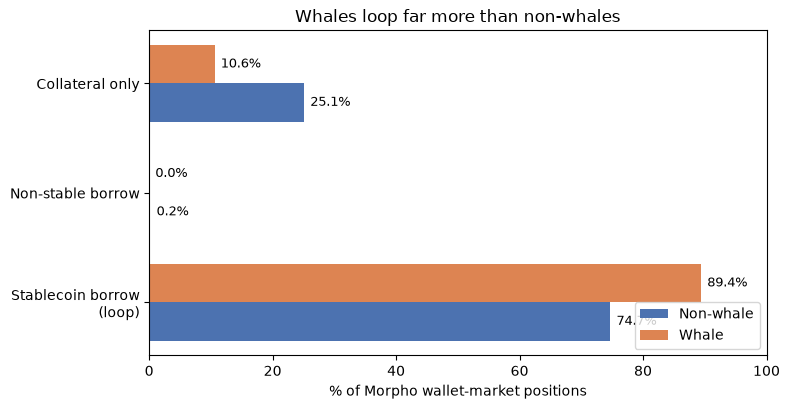

In [11]:
import matplotlib.pyplot as plt
import numpy as np

archetypes = ["collateral_only", "non_stable_borrow", "stablecoin_borrow"]
nonwhale = archetype_by_whale_pct.loc[False, archetypes]
whale = archetype_by_whale_pct.loc[True, archetypes]

y = np.arange(len(archetypes))
h = 0.35

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(y + h/2, nonwhale, height=h, color="#4C72B0", label="Non-whale")
ax.barh(y - h/2, whale, height=h, color="#DD8452", label="Whale")
ax.set_yticks(y)
ax.set_yticklabels(["Collateral only", "Non-stable borrow", "Stablecoin borrow\n(loop)"])
ax.set_xlabel("% of Morpho wallet-market positions")
ax.set_title("Whales loop far more than non-whales")
ax.invert_yaxis()
for i, (nv, wv) in enumerate(zip(nonwhale, whale)):
    ax.text(nv + 1, i + h/2, f"{nv:.1f}%", va="center", fontsize=9)
    ax.text(wv + 1, i - h/2, f"{wv:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
whale_market_share = morpho_ind_whales.groupby(["token_name", "market_id", "loan_token_symbol"]).apply(
    lambda g: pd.Series({
        "whale_collateral_usd": g.loc[g["is_whale"] == True, "collateral_value_usd"].sum(),
        "total_collateral_usd": g["collateral_value_usd"].sum(),
    })
).reset_index()

whale_market_share["whale_share_pct"] = (
    whale_market_share["whale_collateral_usd"] / whale_market_share["total_collateral_usd"] * 100
).round(1)

whale_market_share.sort_values("total_collateral_usd", ascending=False)

,token_name,market_id,loan_token_symbol,whale_collateral_usd,total_collateral_usd,whale_share_pct
31,syrupUSDC,0xc9629945524f3fde56c7e8854a6c3d48e76b9d97236a...,PYUSD,6.522202e+07,7.834306e+07,83.3
2,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,4.862018e+07,6.450778e+07,75.4
20,sUSDe,0x90ef0c5a0dc7c4de4ad4585002d44e9d411d212d2f62...,PYUSD,3.647841e+07,4.219705e+07,86.4
30,syrupUSDC,0xc0ae375fd761ff19b3f04de5534c0f1ec110f80e1c2e...,RLUSD,2.866002e+07,3.715550e+07,77.1
29,syrupUSDC,0xab3196447663a41382ba4b4d55eab3fa702ee2cf071d...,AUSD,2.136963e+07,2.368719e+07,90.2
18,sUSDe,0x88a18b2f4d94e7ad27a381b15531c06abf05a7c99dd5...,USDtb,9.487408e+06,1.130872e+07,83.9
1,sUSDS,0x09cf702bb8b6fe8c6effb6021744e365f598b89bc28f...,AUSD,3.926875e+06,4.242433e+06,92.6
9,sUSDe,0x1247f1c237eceae0602eab1470a5061a6dd8f734ba88...,DAI,1.409512e+01,1.946114e+06,0.0
10,sUSDe,0x39d11026eae1c6ec02aa4c0910778664089cdd97c3fd...,DAI,0.000000e+00,1.751174e+06,0.0
23,sUSDe,0xdc5333039bcf15f1237133f74d5806675d83d9cf19cf...,USDT,0.000000e+00,8.156690e+05,0.0


### Chart: Whale share of collateral, by market

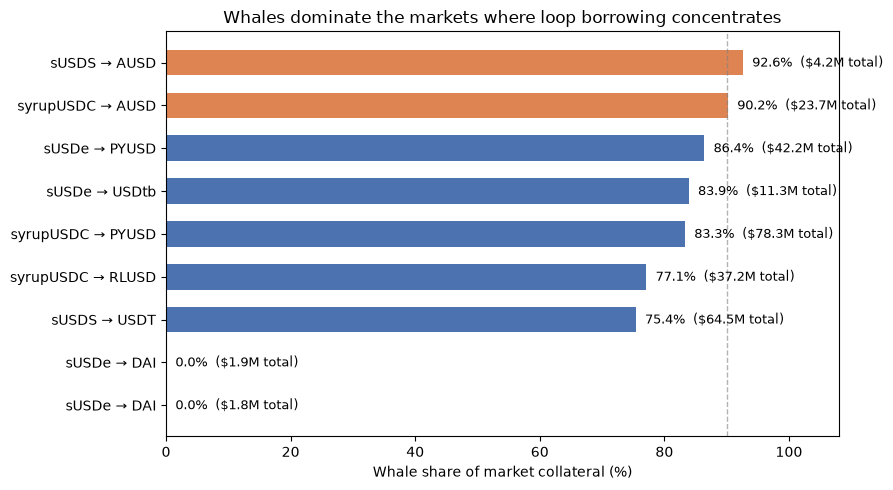

In [13]:
import matplotlib.pyplot as plt
import numpy as np

dom = whale_market_share[whale_market_share["total_collateral_usd"] > 1_000_000].copy()
dom = dom.sort_values("whale_share_pct", ascending=True)
dom["market_label"] = dom["token_name"] + " \u2192 " + dom["loan_token_symbol"]

y = np.arange(len(dom))
colors = ["#DD8452" if s >= 90 else "#4C72B0" for s in dom["whale_share_pct"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y, dom["whale_share_pct"], color=colors, height=0.6)
ax.set_yticks(y)
ax.set_yticklabels(dom["market_label"])
ax.set_xlabel("Whale share of market collateral (%)")
ax.set_xlim(0, 108)
ax.set_title("Whales dominate the markets where loop borrowing concentrates")
ax.axvline(90, color="gray", linestyle="--", linewidth=1, alpha=0.6)

for yi, share, collat in zip(y, dom["whale_share_pct"], dom["total_collateral_usd"] / 1e6):
    ax.text(share + 1.5, yi, f"{share:.1f}%  (${collat:.1f}M total)", va="center", fontsize=9)

plt.tight_layout()
plt.show()

## Whale Behavior

**Approach:** Reused the existing $1M `total_YBS_exposure` whale threshold from the meta-archetype notebook, and joined the operator whale flag (`is_whale`, EOA + Gnosis Safe) onto the market-level Morpho data (`morpho_ind`), matched on `wallet` + `token_name`. This let us check whether whales behave differently from other holders now that we have market-level detail (archetype, collateral value, borrowed amount per market).

**Coverage:** Every wallet-market row is assigned a flag. Recovered Safe (and cache-missed EOA) operators are counted as whales when they clear the $1M threshold; the remaining infrastructure contracts (bundlers, vaults, routers) are treated as non-whale. Of 497 wallet-market positions, 47 are whale positions.

### Archetype mix: whale vs non-whale

| | Collateral only | Non-stable borrow | Stablecoin borrow |
|---|---|---|---|
| Non-whale | 25.1% | 0.2% | 74.7% |
| Whale | 10.6% | 0.0% | 89.4% |

Whales are meaningfully more likely to be actively borrowing against their collateral (89.4% vs 74.7%) and less likely to hold idle, unborrowed collateral (10.6% vs 25.1%). Larger holders skew more toward active leverage, not passive parking.

### Whale share of collateral, by market

For every market with economically meaningful collateral, whales account for the large majority of the total:

| Token | Loan asset | Whale share of collateral |
|---|---|---|
| sUSDS | AUSD | 92.6% |
| syrupUSDC | AUSD | 90.2% |
| sUSDe | PYUSD | 86.4% |
| sUSDe | USDtb | 83.9% |
| syrupUSDC | PYUSD | 83.3% |
| syrupUSDC | RLUSD | 77.1% |
| sUSDS | USDT | 75.4% |

All remaining markets (DAI, msUSD, USDC, tGBP, WETH, and other small pairs) hold negligible total collateral and show 0% whale share, consistent with earlier findings that they are not economically significant.

### Takeaway

Morpho exposure across all three YBS tokens is **concentrated risk, not distributed risk**. The dominant markets are each 75-93% whale-owned, meaning a small number of large positions account for most collateral and borrow activity. This has direct implications for the risk section of the analysis (LTV/APY/risk to other actors): a liquidation event in any of these markets would be driven by a handful of large wallets unwinding, not broad-based retail activity, raising concerns around slippage, cascading liquidations, and oracle stress concentrated around a few addresses.

In [14]:
top_wallets = morpho_ind_whales[
    (morpho_ind_whales["token_name"] == "syrupUSDC") &
    (morpho_ind_whales["loan_token_symbol"] == "PYUSD") &
    (morpho_ind_whales["is_whale"] == True)
].sort_values("collateral_value_usd", ascending=False)

top_wallets[["wallet", "collateral_value_usd", "borrowed_amount"]]

,wallet,collateral_value_usd,borrowed_amount
397,0x7bee8d37fba61a6251a08b957d502c56e2a50fab,5.420592e+07,4.671351e+07
401,0x815f5bb257e88b67216a344c7c83a3ea4ee74748,6.593904e+06,5.728171e+06
407,0xb8b827eafb19df6737935b3b3f6bef855d2f8e84,3.263132e+06,2.794588e+06
416,0xa765a629f11f538f6d67e3fdf799baed1506017d,6.143950e+05,5.310000e+05
420,0x0ccb1da137fbe2ae1e622670d2e6a66d342248b0,5.445945e+05,4.607545e+05
472,0x00c04ae980a41825fcb505797d394090295b5813,6.696096e+01,-6.202554e+02
479,0x20b20eae302c821b53018037b0f3c1ec90c0af5b,6.004604e+00,-5.920000e+02


In [15]:
import pandas as pd

lltv_data = pd.read_csv("from_dune/morpho_market_breakdown_individual.csv")  # your new export
lltv_data["wallet"] = lltv_data["wallet"].str.lower().str.strip()

EXCHANGE_RATES = {
    "syrupUSDC": 1.17,
    "sUSDe": 1.24,
    "sUSDS": 1.10,
}
lltv_data["collateral_value_usd"] = lltv_data["token_name"].map(EXCHANGE_RATES) * lltv_data["collateral_balance"]

NON_USD_LOAN_TOKENS = {"WETH", "tGBP"}
lltv_clean = lltv_data[~lltv_data["loan_token_symbol"].isin(NON_USD_LOAN_TOKENS)].copy()

print(f"Excluded {len(lltv_data) - len(lltv_clean)} rows (WETH/tGBP)")

lltv_clean["current_ltv"] = lltv_clean["borrowed_amount"] / lltv_clean["collateral_value_usd"]
lltv_clean["ltv_utilization"] = lltv_clean["current_ltv"] / lltv_clean["lltv"]

real_positions = lltv_clean[lltv_clean["collateral_value_usd"] > 100].copy()
real_positions.sort_values("ltv_utilization", ascending=False).head(10)


Excluded 2 rows (WETH/tGBP)


,wallet,token_name,market_id,loan_token_symbol,lltv,collateral_balance,borrowed_amount,collateral_value_usd,current_ltv,ltv_utilization
132,0x1fa909909d5501d66f7e20b3f9d0cc5c598f020a,sUSDe,0xdc5333039bcf15f1237133f74d5806675d83d9cf19cf...,USDT,0.915,1.714072e+05,1.997400e+05,2.125449e+05,0.939754,1.027054
138,0x9f1eedb073dba34f8786639b1462db6f2c11ba27,sUSDe,0x85c7f4374f3a403b36d54cc284983b2b02bbd8581ee0...,USDC,0.915,1.176299e+05,1.359794e+05,1.458611e+05,0.932253,1.018856
42,0x7c6b5be711bf85cacff8f4f282b90e0f00f55b3f,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,4.983093e+04,5.297315e+04,5.481403e+04,0.966416,1.001467
3,0x0cd7e1660d63a6aebda782a2eb7f2875716ac3e8,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,3.645471e+06,3.855377e+06,4.010018e+06,0.961436,0.996307
13,0x086eb9c2b14dd657ae77d07df9115a2f946ce327,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,9.582200e+05,1.012489e+06,1.054042e+06,0.960577,0.995417
453,0x1ba659d755c344554dffaa121da938fdf1503823,syrupUSDC,0xc0ae375fd761ff19b3f04de5534c0f1ec110f80e1c2e...,RLUSD,0.915,1.061402e+04,1.128962e+04,1.241840e+04,0.909104,0.993556
415,0xc6dd9976066f3364b4d6a72cd4f1fa0468327aa7,syrupUSDC,0xab3196447663a41382ba4b4d55eab3fa702ee2cf071d...,AUSD,0.915,8.661904e+05,9.209267e+05,1.013443e+06,0.908711,0.993127
50,0xf5dc3af6d78957b1877622335770e6b49459a5d2,sUSDS,0x09cf702bb8b6fe8c6effb6021744e365f598b89bc28f...,AUSD,0.945,2.994496e+04,3.084682e+04,3.293946e+04,0.936470,0.990974
49,0x45b85c2b1dd671151daf22fce5efba0767b78c5b,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,3.252616e+04,3.419445e+04,3.577878e+04,0.955719,0.990382
25,0xaf353cb62fcb4fcf0b1a9d22046a8993c9b03a0b,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,0.965,2.927624e+05,3.076816e+05,3.220386e+05,0.955418,0.990071


## Looping

In [16]:
whale_flags = pd.read_csv("whale_flags_operator.csv")  # EOA + Safe operators, built above
whale_flags["wallet"] = whale_flags["wallet"].str.lower().str.strip()

lltv_clean_whales = lltv_clean.merge(
    whale_flags[["wallet", "token_name", "is_whale"]], on=["wallet", "token_name"], how="left"
)
lltv_clean_whales["is_whale"] = lltv_clean_whales["is_whale"].fillna(False)

print(f"Rows: {len(lltv_clean_whales)}")

print("\n--- By current_ltv threshold ---")
for t in [0.5, 0.6, 0.7, 0.8]:
    tag = lltv_clean_whales["current_ltv"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Threshold {t}: {result.to_dict()}")

print("\n--- By ltv_utilization (real LLTV-adjusted) ---")
for t in [0.7, 0.8, 0.9, 0.95]:
    tag = lltv_clean_whales["ltv_utilization"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Utilization > {t}: {result.to_dict()}")


Rows: 495

--- By current_ltv threshold ---
Threshold 0.5: {False: 62.9, True: 89.4}
Threshold 0.6: {False: 60.699999999999996, True: 89.4}
Threshold 0.7: {False: 54.50000000000001, True: 89.4}
Threshold 0.8: {False: 39.5, True: 87.2}

--- By ltv_utilization (real LLTV-adjusted) ---
Utilization > 0.7: {False: 58.9, True: 89.4}
Utilization > 0.8: {False: 51.6, True: 89.4}
Utilization > 0.9: {False: 32.6, True: 85.1}
Utilization > 0.95: {False: 12.5, True: 27.700000000000003}


## What % Does Looping

**Proxy used:** `ltv_utilization` = current LTV / market's real LLTV. Measures how close a wallet is to the max leverage their market allows.

| Utilization | Non-whale | Whale |
|---|---|---|
| > 70% | 58.9% | 89.4% |
| > 80% | 51.6% | 89.4% |
| > 90% | 32.6% | 85.1% |
| > 95% | 12.5% | 27.7% |

**Finding:** ~85% of whale positions are borrowed at 90%+ of their market's max LTV, vs ~33% of non-whales, a ~2.6x gap. Whales cluster tightly near the leverage ceiling; non-whales are more spread out.

**Caveat:** This measures leverage intensity, not confirmed looping (would need to trace whether borrowed funds bought more YBS). But the pattern is strongly consistent with active looping among whales.

### Chart: Leverage vs liquidation ceiling, whale vs non-whale

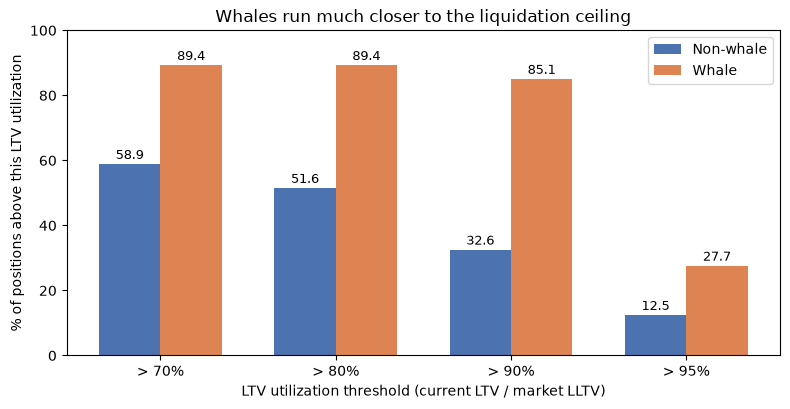

In [17]:
import matplotlib.pyplot as plt
import numpy as np

thresholds = [0.7, 0.8, 0.9, 0.95]
rows = []
for t in thresholds:
    tag = lltv_clean_whales["ltv_utilization"] > t
    result = tag.groupby(lltv_clean_whales["is_whale"]).mean() * 100
    rows.append({"threshold": t, "nonwhale": result.get(False, 0), "whale": result.get(True, 0)})

util_df = pd.DataFrame(rows)

x = np.arange(len(util_df))
w = 0.35

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - w/2, util_df["nonwhale"], width=w, color="#4C72B0", label="Non-whale")
ax.bar(x + w/2, util_df["whale"], width=w, color="#DD8452", label="Whale")
ax.set_xticks(x)
ax.set_xticklabels([f"> {int(t*100)}%" for t in util_df["threshold"]])
ax.set_ylabel("% of positions above this LTV utilization")
ax.set_xlabel("LTV utilization threshold (current LTV / market LLTV)")
ax.set_title("Whales run much closer to the liquidation ceiling")
ax.set_ylim(0, 100)
for i, row in util_df.iterrows():
    ax.text(i - w/2, row["nonwhale"] + 1.5, f"{row['nonwhale']:.1f}", ha="center", fontsize=9)
    ax.text(i + w/2, row["whale"] + 1.5, f"{row['whale']:.1f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

# Risks to them

In [18]:
# distance to liquidation, expressed as % price drop the collateral could take before hitting LLTV
lltv_clean_whales["price_drop_to_liquidation_pct"] = (
    (1 - lltv_clean_whales["ltv_utilization"]) * 100
).clip(lower=0)

# summary stats, whale vs non-whale
risk_to_them = lltv_clean_whales.groupby("is_whale")["price_drop_to_liquidation_pct"].describe()
risk_to_them

,count,mean,std,min,25%,50%,75%,max
is_whale,,,,,,,,
False,448.0,22522.252952,179881.516177,0.000000,7.858873,18.990315,100.000000,2.897740e+06
True,47.0,308.494350,1599.230776,0.369286,4.688674,5.957681,8.068619,1.087497e+04


In [19]:
# how many wallets are within a "danger zone" - can't absorb even a small price move
for buffer in [1, 2, 5, 10]:
    at_risk = lltv_clean_whales["price_drop_to_liquidation_pct"] < buffer
    result = at_risk.groupby(lltv_clean_whales["is_whale"]).mean().round(3) * 100
    print(f"Within {buffer}% of liquidation: {result.to_dict()}")

Within 1% of liquidation: {False: 1.7999999999999998, True: 4.3}
Within 2% of liquidation: {False: 4.2, True: 6.4}
Within 5% of liquidation: {False: 12.5, True: 27.700000000000003}
Within 10% of liquidation: {False: 32.6, True: 85.1}


### Chart: Distance to liquidation, whale vs non-whale

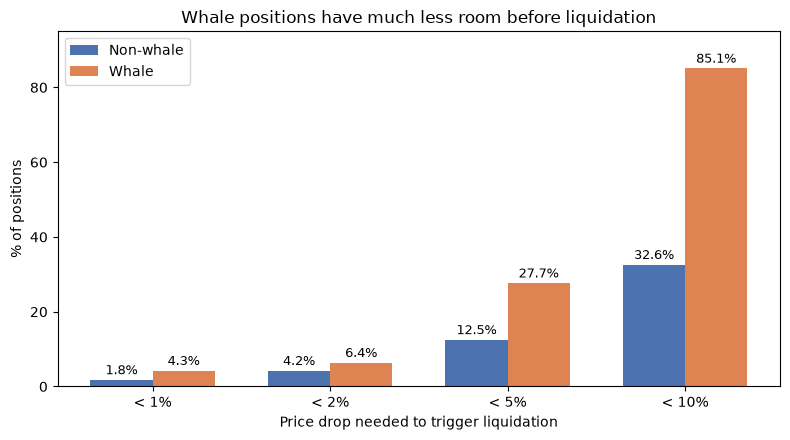

In [20]:
import matplotlib.pyplot as plt
import numpy as np

buffers = [1, 2, 5, 10]
rows = []
for b in buffers:
    at_risk = lltv_clean_whales["price_drop_to_liquidation_pct"] < b
    result = at_risk.groupby(lltv_clean_whales["is_whale"]).mean() * 100
    rows.append({"buffer": b, "nonwhale": result.get(False, 0), "whale": result.get(True, 0)})

dist_df = pd.DataFrame(rows)

x = np.arange(len(dist_df))
w = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, dist_df["nonwhale"], width=w, color="#4C72B0", label="Non-whale")
ax.bar(x + w/2, dist_df["whale"], width=w, color="#DD8452", label="Whale")
ax.set_xticks(x)
ax.set_xticklabels([f"< {b}%" for b in dist_df["buffer"]])
ax.set_ylabel("% of positions")
ax.set_xlabel("Price drop needed to trigger liquidation")
ax.set_title("Whale positions have much less room before liquidation")
ax.set_ylim(0, 95)

for i, row in dist_df.iterrows():
    ax.text(i - w/2, row["nonwhale"] + 1.5, f"{row['nonwhale']:.1f}%", ha="center", fontsize=9)
    ax.text(i + w/2, row["whale"] + 1.5, f"{row['whale']:.1f}%", ha="center", fontsize=9)

ax.legend()
plt.tight_layout()
plt.show()

## Risk to Them: Distance to Liquidation

**Measure:** % price drop a wallet's collateral could absorb before hitting their market's liquidation threshold (`(1 - ltv_utilization) * 100`).

| Buffer remaining | Non-whale | Whale |
|---|---|---|
| Within 1% of liquidation | 1.8% | 4.3% |
| Within 2% of liquidation | 4.2% | 6.4% |
| Within 5% of liquidation | 12.5% | 27.7% |
| Within 10% of liquidation | 32.6% | 85.1% |

**Finding:** **85.1% of whale positions** would be liquidated by a 10% adverse price move, compared to **32.6% of non-whale positions**, roughly 2.6x the exposure. Even at a tighter 5% move, over a quarter of whale positions (27.7%) would be liquidated.

**Interpretation:** Whales aren't just more leveraged on average, most of them are running with very little safety margin. A price move well within normal market volatility for a crypto-adjacent asset (a de-peg, a sharp sell-off, an oracle lag) would be enough to liquidate the large majority of whale positions in this dataset, exposing them directly to the liquidation penalty on top of losing their position.

In [21]:
market_risk = lltv_clean_whales.groupby(["token_name", "market_id", "loan_token_symbol"]).apply(
    lambda g: pd.Series({
        "total_collateral_usd": g["collateral_value_usd"].sum(),
        "at_risk_collateral_usd": g.loc[g["price_drop_to_liquidation_pct"] < 5, "collateral_value_usd"].sum(),
        "largest_position_usd": g["collateral_value_usd"].max(),
    })
).reset_index()

market_risk["at_risk_share_pct"] = (
    market_risk["at_risk_collateral_usd"] / market_risk["total_collateral_usd"] * 100
).round(1)
market_risk["largest_position_share_pct"] = (
    market_risk["largest_position_usd"] / market_risk["total_collateral_usd"] * 100
).round(1)

MIN_MARKET_SIZE = 100_000  # $100k threshold, adjust as needed
market_risk_filtered = market_risk[market_risk["total_collateral_usd"] > MIN_MARKET_SIZE]

market_risk_filtered.sort_values("total_collateral_usd", ascending=False)

,token_name,market_id,loan_token_symbol,total_collateral_usd,at_risk_collateral_usd,largest_position_usd,at_risk_share_pct,largest_position_share_pct
29,syrupUSDC,0xc9629945524f3fde56c7e8854a6c3d48e76b9d97236a...,PYUSD,7.834306e+07,0.000000e+00,5.420592e+07,0.0,69.2
2,sUSDS,0x3274643db77a064abd3bc851de77556a4ad2e2f502f4...,USDT,6.450778e+07,2.724280e+07,2.688659e+07,42.2,41.7
18,sUSDe,0x90ef0c5a0dc7c4de4ad4585002d44e9d411d212d2f62...,PYUSD,4.219705e+07,1.994844e+07,1.436067e+07,47.3,34.0
28,syrupUSDC,0xc0ae375fd761ff19b3f04de5534c0f1ec110f80e1c2e...,RLUSD,3.715550e+07,7.501316e+06,9.105966e+06,20.2,24.5
27,syrupUSDC,0xab3196447663a41382ba4b4d55eab3fa702ee2cf071d...,AUSD,2.368719e+07,1.564812e+06,7.895153e+06,6.6,33.3
16,sUSDe,0x88a18b2f4d94e7ad27a381b15531c06abf05a7c99dd5...,USDtb,1.130872e+07,1.582366e+06,4.142548e+06,14.0,36.6
1,sUSDS,0x09cf702bb8b6fe8c6effb6021744e365f598b89bc28f...,AUSD,4.242433e+06,3.293946e+04,2.587392e+06,0.8,61.0
7,sUSDe,0x1247f1c237eceae0602eab1470a5061a6dd8f734ba88...,DAI,1.946114e+06,3.747535e+05,6.191676e+05,19.3,31.8
8,sUSDe,0x39d11026eae1c6ec02aa4c0910778664089cdd97c3fd...,DAI,1.751174e+06,7.817366e+04,1.208180e+06,4.5,69.0
21,sUSDe,0xdc5333039bcf15f1237133f74d5806675d83d9cf19cf...,USDT,8.156690e+05,4.739346e+05,2.125449e+05,58.1,26.1


### Chart: At-risk collateral vs largest-wallet concentration, by market

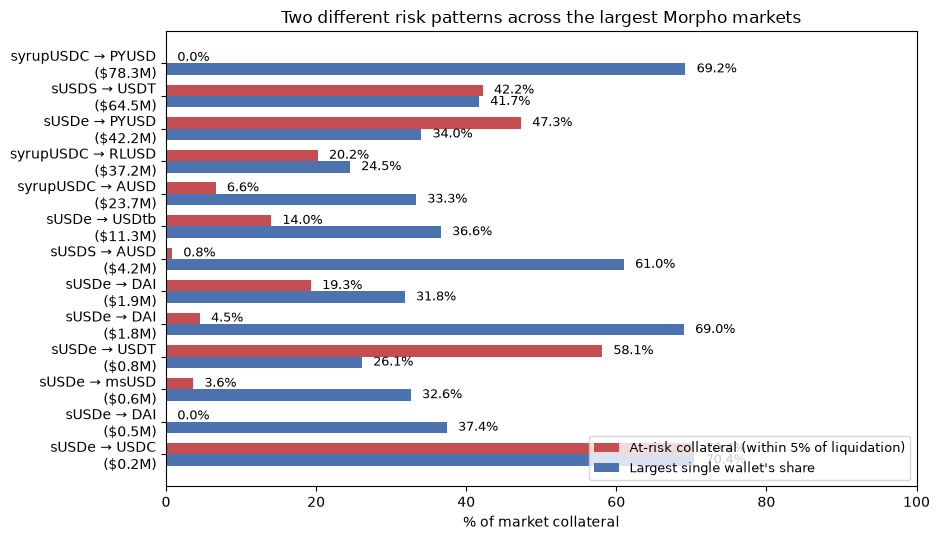

In [22]:
import matplotlib.pyplot as plt
import numpy as np

risk_plot = market_risk_filtered.sort_values("total_collateral_usd", ascending=False).copy()
risk_plot["market_label"] = (
    risk_plot["token_name"] + " \u2192 " + risk_plot["loan_token_symbol"]
    + "\n($" + (risk_plot["total_collateral_usd"] / 1e6).round(1).astype(str) + "M)"
)

y = np.arange(len(risk_plot))[::-1]
h = 0.35

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.barh(y + h/2, risk_plot["at_risk_share_pct"], height=h, color="#C44E52",
        label="At-risk collateral (within 5% of liquidation)")
ax.barh(y - h/2, risk_plot["largest_position_share_pct"], height=h, color="#4C72B0",
        label="Largest single wallet's share")
ax.set_yticks(y)
ax.set_yticklabels(risk_plot["market_label"])
ax.set_xlabel("% of market collateral")
ax.set_xlim(0, 100)
ax.set_title("Two different risk patterns across the largest Morpho markets")

for yi, ar, lw in zip(y, risk_plot["at_risk_share_pct"], risk_plot["largest_position_share_pct"]):
    ax.text(ar + 1.5, yi + h/2, f"{ar:.1f}%", va="center", fontsize=9)
    ax.text(lw + 1.5, yi - h/2, f"{lw:.1f}%", va="center", fontsize=9)

ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Risk to Other Actors: Market-Level Exposure

**Measured per market (only markets over $1M collateral):** how much sits in the single biggest wallet, and how much is within 5% of liquidation right now.

| Market | Total collateral | At-risk (within 5%) | Largest wallet's share |
|---|---|---|---|
| syrupUSDC / PYUSD | $78.3M | 0.0% | 69.2% |
| sUSDS / USDT | $64.5M | 42.2% | 41.7% |
| sUSDe / PYUSD | $42.2M | 47.3% | 34.0% |
| syrupUSDC / RLUSD | $37.2M | 20.2% | 24.5% |
| syrupUSDC / AUSD | $23.7M | 6.6% | 33.3% |
| sUSDe / USDtb | $11.3M | 14.0% | 36.6% |
| sUSDS / AUSD | $4.2M | 0.8% | 61.0% |

**Key finding:** Every market is dominated by one wallet (25-69% of the market). Two markets are especially risky right now: **sUSDS/USDT** and **sUSDe/PYUSD** both have a large share of collateral (42-47%) sitting close to liquidation. If the top wallet gets liquidated there, it could push nearby positions over the edge too, a cascade.

**Takeaway:** These markets depend heavily on a small number of large wallets. A liquidation isn't a small, isolated event, it moves a big share of the market at once and could trigger further liquidations, slippage, or bad debt for other lenders.

## What is APY? Is the loop profitable?

The last open question. A whale deposits a yield-bearing stablecoin (YBS) as collateral, borrows a
stablecoin against it, swaps back into more YBS and repeats. The trade only makes sense if what the
collateral earns beats what it costs to borrow.

Per market we compute the **spread** the way Dawid framed it:

`spread = native YBS APY + Morpho supply APY - Morpho borrow APY`

- **native YBS APY** - yield the collateral keeps earning while it sits in Morpho (Ethena / Sky / Maple).
- **Morpho supply APY** - what the loan-token side pays lenders.
- **Morpho borrow APY** - the cost the looper pays to borrow.

A positive spread in the markets whales actually concentrate in (PYUSD, USDT, RLUSD, AUSD) means the
leverage is a rational, profitable trade rather than reckless risk-taking.

In [23]:
import requests

# Morpho Blue public API - live supply/borrow APY for every market where our YBS is collateral
YBS_ADDRS = {
    "syrupUSDC": "0x80ac24aA929eaF5013f6436cdA2a7ba190f5Cc0b",
    "sUSDe":     "0x9D39A5DE30e57443BfF2A8307A4256c8797A3497",
    "sUSDS":     "0xa3931d71877C0E7a3148CB7Eb4463524FEc27fbD",
}

MORPHO_API = "https://blue-api.morpho.org/graphql"
QUERY = """
query($addrs: [String!]) {
  markets(first: 1000, where: {chainId_in: [1], collateralAssetAddress_in: $addrs}) {
    items { marketId loanAsset { symbol } state { supplyApy borrowApy } }
  }
}
"""

APY_CACHE = "morpho_apy_cache.csv"  # so reruns work even if the API is down

def fetch_morpho_apy():
    resp = requests.post(MORPHO_API, json={"query": QUERY, "variables": {"addrs": list(YBS_ADDRS.values())}}, timeout=30)
    resp.raise_for_status()
    items = resp.json()["data"]["markets"]["items"]
    rows = [{
        "market_id": m["marketId"],
        "supply_apy": m["state"]["supplyApy"] * 100,   # API returns a fraction, convert to %
        "borrow_apy": m["state"]["borrowApy"] * 100,
    } for m in items]
    return pd.DataFrame(rows)

try:
    market_apy = fetch_morpho_apy()
    market_apy.to_csv(APY_CACHE, index=False)
    print(f"Fetched supply/borrow APY for {len(market_apy)} markets from Morpho")
except Exception as e:
    print("Morpho API failed, loading cached APY:", e)
    market_apy = pd.read_csv(APY_CACHE)

market_apy.head()

Fetched supply/borrow APY for 46 markets from Morpho


,market_id,supply_apy,borrow_apy
0,0xf8680eb9c4fcd2be3d155cf7b1b0a2b56c6ad8c67bee...,8.584669,9.070317
1,0xf385878b1d2c6581b8ec2fde0497de94f670c05f9506...,0.000000,0.263389
2,0xe475337d11be1db07f7c5a156e511f05d1844308e66e...,7.600265,8.421830
3,0xdcfd3558f75a13a3c430ee71df056b5570cbd628da91...,0.003345,0.033363
4,0xdc5333039bcf15f1237133f74d5806675d83d9cf19cf...,3.535046,4.037779


In [24]:
# native YBS yield - the collateral keeps earning while it sits in Morpho.
# pulled from DeFiLlama; falls back to documented values (2026-07-14) if offline.
NATIVE_APY_FALLBACK = {
    "syrupUSDC": 4.86,   # Maple USDC pool
    "sUSDe":     3.96,   # Ethena staked USDe
    "sUSDS":     3.60,   # Sky Savings Rate
}

LLAMA_POOLS = {   # (symbol, project) of the canonical native pool on DeFiLlama
    "syrupUSDC": ("USDC", "maple"),
    "sUSDe":     ("SUSDE", "ethena-usde"),
    "sUSDS":     ("SUSDS", "sky-lending"),
}

def fetch_native_apy():
    pools = requests.get("https://yields.llama.fi/pools", timeout=30).json()["data"]
    out = {}
    for token, (sym, proj) in LLAMA_POOLS.items():
        cands = [p for p in pools if p["symbol"] == sym and proj in p["project"]]
        cands = sorted(cands, key=lambda p: p.get("tvlUsd", 0), reverse=True)
        out[token] = round(cands[0]["apy"], 2) if cands else NATIVE_APY_FALLBACK[token]
    return out

try:
    NATIVE_APY = fetch_native_apy()
except Exception as e:
    print("Llama fetch failed, using fallback:", e)
    NATIVE_APY = NATIVE_APY_FALLBACK

NATIVE_APY

{'syrupUSDC': 4.85, 'sUSDe': 3.92, 'sUSDS': 3.6}

In [25]:
# bring the APYs onto the per-market summary and compute the spread
apy_table = market_summary.merge(market_apy, on="market_id", how="left")
apy_table["market_label"] = apy_table["token_name"] + " → " + apy_table["loan_token_symbol"]
apy_table["native_apy"] = apy_table["token_name"].map(NATIVE_APY)

# Dawid's spread: what the collateral earns (native + Morpho supply) minus the borrow cost
apy_table["net_spread"] = apy_table["native_apy"] + apy_table["supply_apy"] - apy_table["borrow_apy"]
apy_table["loop_carry"] = apy_table["native_apy"] - apy_table["borrow_apy"]   # core carry, ignoring the supply side
apy_table["is_profitable"] = apy_table["net_spread"] > 0

apy_table = apy_table.sort_values("total_collateral_usd", ascending=False)

cols = ["market_label", "num_wallets", "total_collateral_usd",
        "native_apy", "supply_apy", "borrow_apy", "net_spread", "loop_carry", "is_profitable"]
apy_table[cols].round(2)

,market_label,num_wallets,total_collateral_usd,native_apy,supply_apy,borrow_apy,net_spread,loop_carry,is_profitable
26,syrupUSDC → PYUSD,25,78343057.00,4.85,3.98,4.42,4.40,0.43,True
0,sUSDS → USDT,88,64507784.53,3.60,2.59,2.87,3.32,0.73,True
9,sUSDe → PYUSD,25,42197053.99,3.92,2.84,3.20,3.56,0.72,True
27,syrupUSDC → RLUSD,27,37155500.46,4.85,3.97,4.41,4.41,0.44,True
28,syrupUSDC → AUSD,23,23687189.63,4.85,8.36,8.85,4.36,-4.00,True
10,sUSDe → USDtb,29,11308718.53,3.92,6.05,6.69,3.28,-2.77,True
1,sUSDS → AUSD,13,4242432.90,3.60,6.74,7.26,3.08,-3.66,True
11,sUSDe → DAI,63,1946114.27,3.92,7.23,8.31,2.84,-4.39,True
12,sUSDe → DAI,37,1751173.98,3.92,7.22,8.08,3.06,-4.16,True
13,sUSDe → USDT,53,815669.05,3.92,3.54,4.04,3.42,-0.12,True


## Are whales piling into positive-spread markets?

Checking the four markets where whale borrowing actually concentrates: PYUSD, USDT, RLUSD, AUSD.

In [26]:
# do the markets whales actually pile into carry a positive spread?
whale_apy = whale_market_share.merge(
    apy_table[["market_id", "net_spread", "loop_carry", "is_profitable"]],
    on="market_id", how="left"
)

WHALE_MARKETS = ["PYUSD", "USDT", "RLUSD", "AUSD"]  # where whale borrowing concentrates
focus = whale_apy[whale_apy["loan_token_symbol"].isin(WHALE_MARKETS)].copy()
focus = focus.sort_values("whale_collateral_usd", ascending=False)

print("Spread in the markets whales concentrate in:\n")
for _, r in focus.iterrows():
    verdict = "PROFITABLE" if r["net_spread"] > 0 else "unprofitable"
    print(f"  {r['token_name']:>9} → {r['loan_token_symbol']:<6}"
          f"  whale collateral ${r['whale_collateral_usd']:>14,.0f}"
          f"  net spread {r['net_spread']:+6.2f}%  ({verdict})")

# whale-collateral-weighted average spread across those markets
w = focus["whale_collateral_usd"]
wavg = (focus["net_spread"] * w).sum() / w.sum()
print(f"\nWhale-collateral-weighted net spread: {wavg:+.2f}%")
if wavg > 0:
    print("=> Whales are concentrated in positive-spread loops: the leverage is currently a rational, profitable trade,")
    print("   since the YBS yields more than it costs to borrow against it.")
else:
    print("=> Whale-concentrated markets are not currently positive-spread.")

Spread in the markets whales concentrate in:

  syrupUSDC → PYUSD   whale collateral $    65,222,021  net spread  +4.40%  (PROFITABLE)
      sUSDS → USDT    whale collateral $    48,620,182  net spread  +3.32%  (PROFITABLE)
      sUSDe → PYUSD   whale collateral $    36,478,407  net spread  +3.56%  (PROFITABLE)
  syrupUSDC → RLUSD   whale collateral $    28,660,019  net spread  +4.41%  (PROFITABLE)
  syrupUSDC → AUSD    whale collateral $    21,369,627  net spread  +4.36%  (PROFITABLE)
      sUSDS → AUSD    whale collateral $     3,926,875  net spread  +3.08%  (PROFITABLE)
      sUSDS → RLUSD   whale collateral $             0  net spread  +3.54%  (PROFITABLE)
      sUSDS → USDT    whale collateral $             0  net spread -2728.50%  (unprofitable)
      sUSDS → PYUSD   whale collateral $             0  net spread  +1.05%  (PROFITABLE)
      sUSDe → AUSD    whale collateral $             0  net spread  -9.42%  (unprofitable)
      sUSDe → RLUSD   whale collateral $             0  ne

### Chart: Loop profitability (APY decomposition) in the markets whales concentrate in

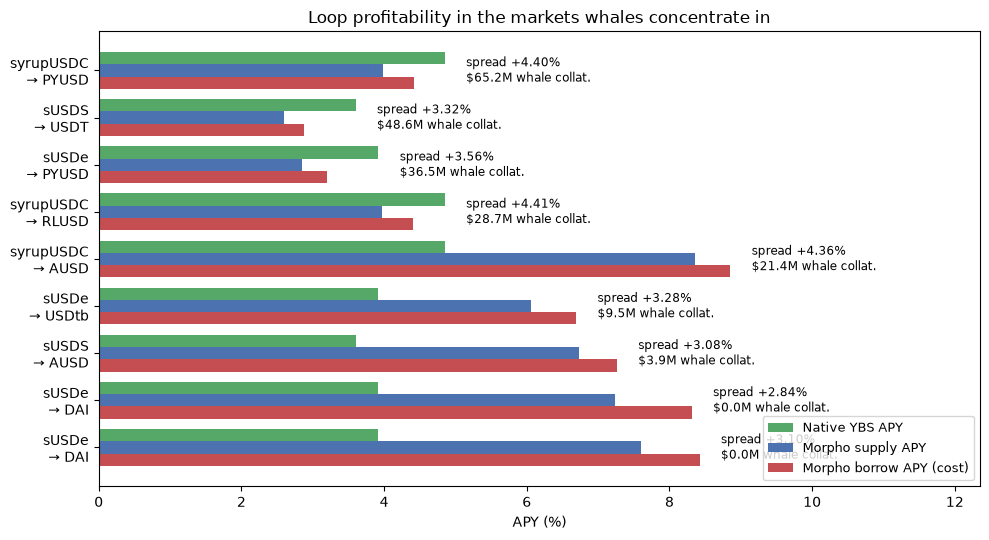

In [27]:
import matplotlib.pyplot as plt
import numpy as np

top_focus = whale_apy.merge(
    apy_table[["market_id", "native_apy", "supply_apy", "borrow_apy"]],
    on="market_id", how="left"
)
top_focus = top_focus[top_focus["whale_collateral_usd"] > 0].sort_values(
    "whale_collateral_usd", ascending=False
)

labels = [f"{r.token_name}\n\u2192 {r.loan_token_symbol}" for r in top_focus.itertuples()]
y = np.arange(len(labels))[::-1]
h = 0.26

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(y + h, top_focus["native_apy"], height=h, label="Native YBS APY", color="#55A868")
ax.barh(y, top_focus["supply_apy"], height=h, label="Morpho supply APY", color="#4C72B0")
ax.barh(y - h, top_focus["borrow_apy"], height=h, label="Morpho borrow APY (cost)", color="#C44E52")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("APY (%)")
ax.set_title("Loop profitability in the markets whales concentrate in")
for yi, row in zip(y, top_focus.itertuples()):
    m = max(row.native_apy, row.supply_apy, row.borrow_apy)
    ax.text(
        m + 0.3, yi,
        f"spread +{row.net_spread:.2f}%\n${row.whale_collateral_usd/1e6:.1f}M whale collat.",
        va="center", fontsize=8.5
    )
ax.set_xlim(0, top_focus[["native_apy", "supply_apy", "borrow_apy"]].values.max() + 3.5)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Charts

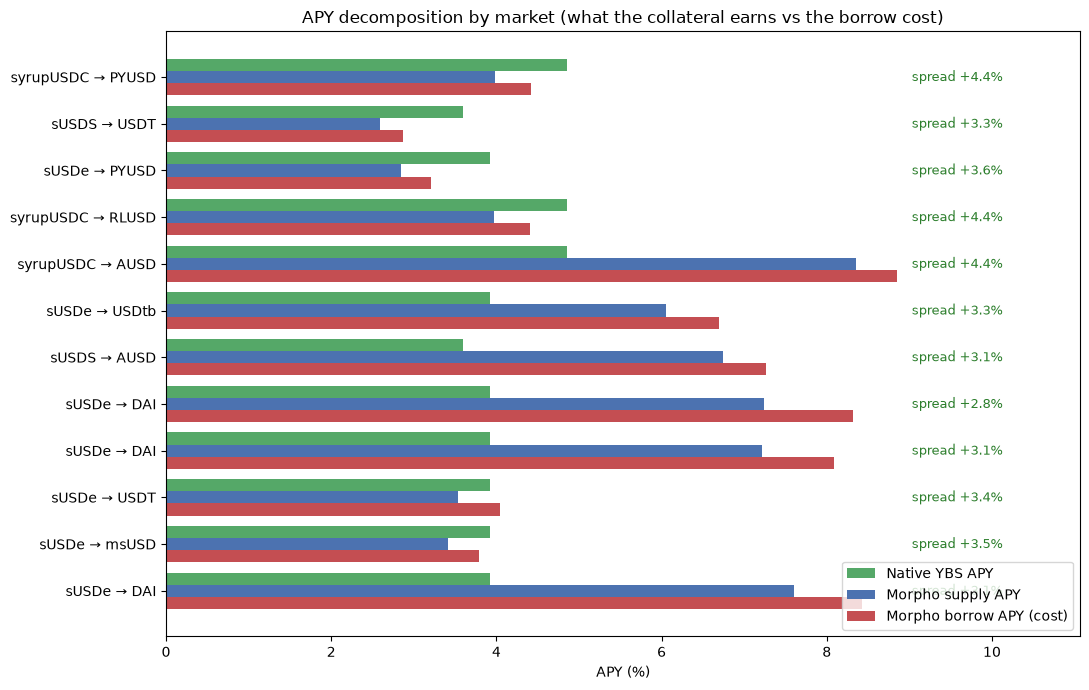

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# APY decomposition for the biggest markets: what the collateral earns vs what it costs
top = apy_table.dropna(subset=["net_spread"]).head(12).iloc[::-1]   # largest at top
y = np.arange(len(top))
h = 0.26

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(y + h, top["native_apy"], height=h, label="Native YBS APY", color="#55A868")
ax.barh(y,     top["supply_apy"], height=h, label="Morpho supply APY", color="#4C72B0")
ax.barh(y - h, top["borrow_apy"], height=h, label="Morpho borrow APY (cost)", color="#C44E52")

ax.set_yticks(y)
ax.set_yticklabels(top["market_label"])
ax.set_xlabel("APY (%)")
ax.set_title("APY decomposition by market (what the collateral earns vs the borrow cost)")
ax.legend(loc="lower right")

xmax = top[["native_apy", "supply_apy", "borrow_apy"]].max().max()
for i, s in zip(y, top["net_spread"]):
    ax.annotate(f"spread {s:+.1f}%", (xmax * 1.02, i), va="center", fontsize=9,
                color=("#2a7d2a" if s > 0 else "#b02a2a"))
ax.set_xlim(0, xmax * 1.25)

plt.tight_layout()
plt.show()

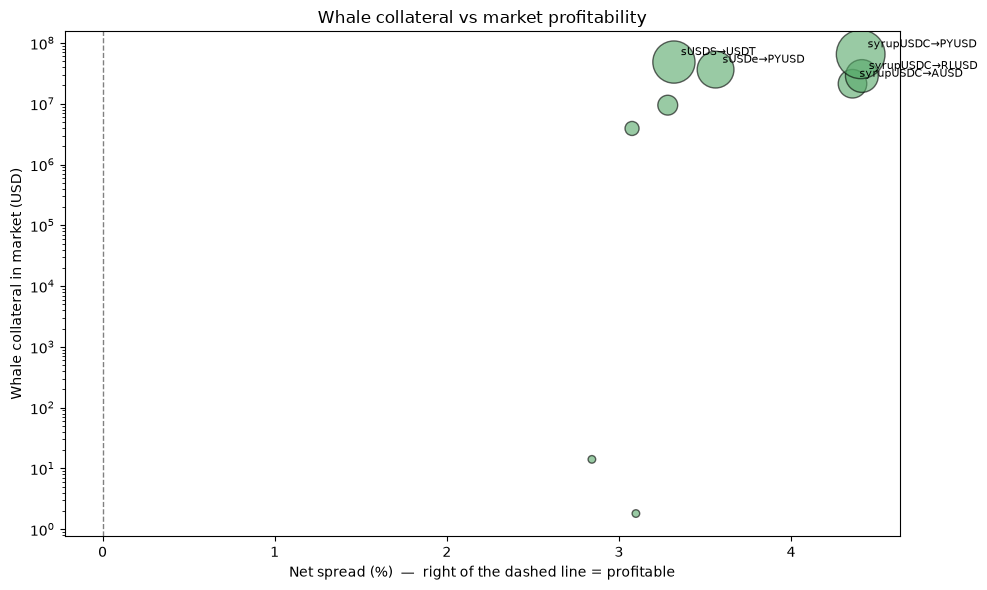

In [29]:
# do whales cluster in the profitable markets? size = whale collateral, x = net spread
plot_df = whale_apy.dropna(subset=["net_spread"])
plot_df = plot_df[plot_df["whale_collateral_usd"] > 0]

fig, ax = plt.subplots(figsize=(10, 6))
sizes = plot_df["whale_collateral_usd"] / plot_df["whale_collateral_usd"].max() * 1200 + 30
point_colors = np.where(plot_df["net_spread"] > 0, "#55A868", "#C44E52")

ax.scatter(plot_df["net_spread"], plot_df["whale_collateral_usd"], s=sizes, c=point_colors, alpha=0.6, edgecolors="k")
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Net spread (%)  —  right of the dashed line = profitable")
ax.set_ylabel("Whale collateral in market (USD)")
ax.set_yscale("log")
ax.set_title("Whale collateral vs market profitability")

for _, r in plot_df.sort_values("whale_collateral_usd", ascending=False).head(5).iterrows():
    ax.annotate(f"{r['token_name']}→{r['loan_token_symbol']}",
                (r["net_spread"], r["whale_collateral_usd"]), fontsize=8,
                xytext=(5, 5), textcoords="offset points")

plt.tight_layout()
plt.show()

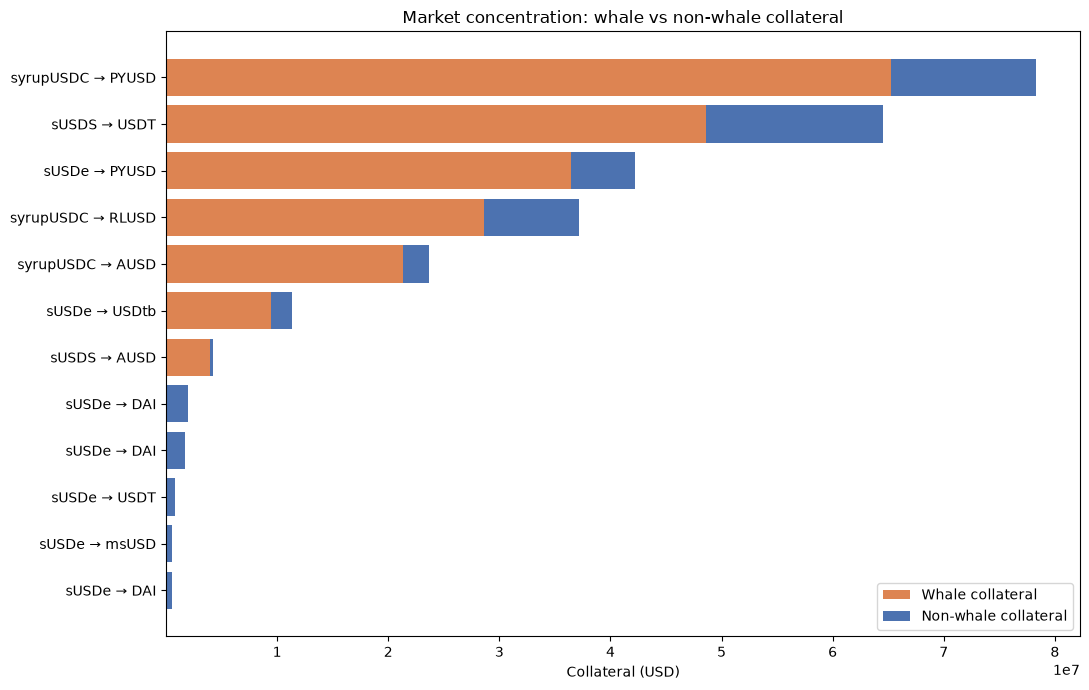

In [30]:
# market concentration split into whale vs non-whale collateral
conc = whale_market_share.copy()
conc["market_label"] = conc["token_name"] + " → " + conc["loan_token_symbol"]
conc["nonwhale_collateral_usd"] = (conc["total_collateral_usd"] - conc["whale_collateral_usd"]).clip(lower=0)
conc = conc.sort_values("total_collateral_usd", ascending=False).head(12).iloc[::-1]

y = np.arange(len(conc))
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(y, conc["whale_collateral_usd"], color="#DD8452", label="Whale collateral")
ax.barh(y, conc["nonwhale_collateral_usd"], left=conc["whale_collateral_usd"], color="#4C72B0", label="Non-whale collateral")
ax.set_yticks(y)
ax.set_yticklabels(conc["market_label"])
ax.set_xlabel("Collateral (USD)")
ax.set_title("Market concentration: whale vs non-whale collateral")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

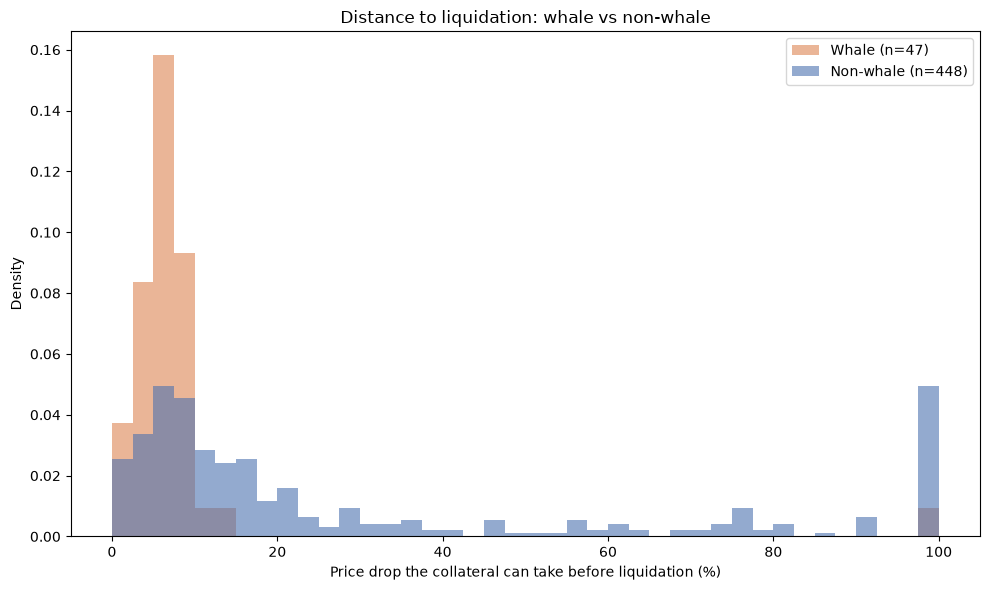

In [31]:
# how close to liquidation are positions - whale vs non-whale
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 100, 41)

for flag, label, color in [(True, "Whale", "#DD8452"), (False, "Non-whale", "#4C72B0")]:
    vals = lltv_clean_whales.loc[lltv_clean_whales["is_whale"] == flag, "price_drop_to_liquidation_pct"].dropna()
    ax.hist(vals, bins=bins, alpha=0.6, label=f"{label} (n={len(vals)})", color=color, density=True)

ax.set_xlabel("Price drop the collateral can take before liquidation (%)")
ax.set_ylabel("Density")
ax.set_title("Distance to liquidation: whale vs non-whale")
ax.legend()

plt.tight_layout()
plt.show()

## Operators: EOA + Safe, and its impact

Every whale figure above already uses the combined operator definition (EOA + Gnosis
Safe) built at the top of the notebook. This section shows what that inclusion changes
against counting externally owned accounts only, reusing the two saved flag files so it
adds no further on-chain calls. The Safe detection itself (reading storage slot~0 and
matching known Safe singletons) mirrors the Aave notebook and is cached in
`safe_type_cache.json`; the shared `address_type_cache.json` is left untouched.


In [32]:
# EOA-only vs EOA + Safe whale dominance, from the two saved flag files (no new RPC)
whale_flags_eoa = pd.read_csv("whale_flags.csv").rename(columns={"token": "token_name"})
whale_flags_eoa["wallet"] = whale_flags_eoa["wallet"].str.lower().str.strip()
whale_flags_op = pd.read_csv("whale_flags_operator.csv")
whale_flags_op["wallet"] = whale_flags_op["wallet"].str.lower().str.strip()


def whale_collateral_share(flag_df, label):
    m = morpho_ind.merge(flag_df[["wallet", "token_name", "is_whale"]], on=["wallet", "token_name"], how="left")
    m["is_whale"] = m["is_whale"].fillna(False)
    m["market_label"] = m["token_name"] + " \u2192 " + m["loan_token_symbol"]
    by_market = m.groupby("market_label").apply(
        lambda g: 100 * g.loc[g["is_whale"], "collateral_value_usd"].sum() / g["collateral_value_usd"].sum()
        if g["collateral_value_usd"].sum() else 0.0
    ).round(1)
    by_market.name = label
    return m, by_market


m_eoa, share_eoa = whale_collateral_share(whale_flags_eoa, "EOA only")
m_op, share_op = whale_collateral_share(whale_flags_op, "EOA + Safe")
comparison = pd.concat([share_eoa, share_op], axis=1)
comparison["delta"] = (comparison["EOA + Safe"] - comparison["EOA only"]).round(1)
print("Whale share of collateral by market (%):")
comparison.sort_values("EOA + Safe", ascending=False)


Whale share of collateral by market (%):


,EOA only,EOA + Safe,delta
market_label,,,
sUSDS → AUSD,92.6,92.6,0.0
syrupUSDC → AUSD,90.2,90.2,0.0
sUSDe → PYUSD,86.4,86.4,0.0
sUSDe → USDtb,34.6,83.9,49.3
syrupUSDC → PYUSD,83.3,83.3,0.0
syrupUSDC → RLUSD,73.4,77.1,3.7
sUSDS → USDT,75.4,75.4,0.0
sUSDS → WETH,0.0,0.0,0.0
sUSDS → USDtb,0.0,0.0,0.0


In [33]:
n_whales_eoa = int(m_eoa["is_whale"].sum())
n_whales_op = int(m_op["is_whale"].sum())
share_eoa_total = 100 * m_eoa.loc[m_eoa["is_whale"], "collateral_value_usd"].sum() / m_eoa["collateral_value_usd"].sum()
share_op_total = 100 * m_op.loc[m_op["is_whale"], "collateral_value_usd"].sum() / m_op["collateral_value_usd"].sum()
print(f"Whale positions   EOA only: {n_whales_eoa}   EOA + Safe: {n_whales_op}")
print(f"Whale collateral share   EOA only: {share_eoa_total:.1f}%   EOA + Safe: {share_op_total:.1f}%")


Whale positions   EOA only: 44   EOA + Safe: 47
Whale collateral share   EOA only: 77.3%   EOA + Safe: 79.9%


Whale positions  EOA only: 44   EOA + Safe: 47
Whale collateral share  EOA only: 77.3%   EOA + Safe: 79.9%


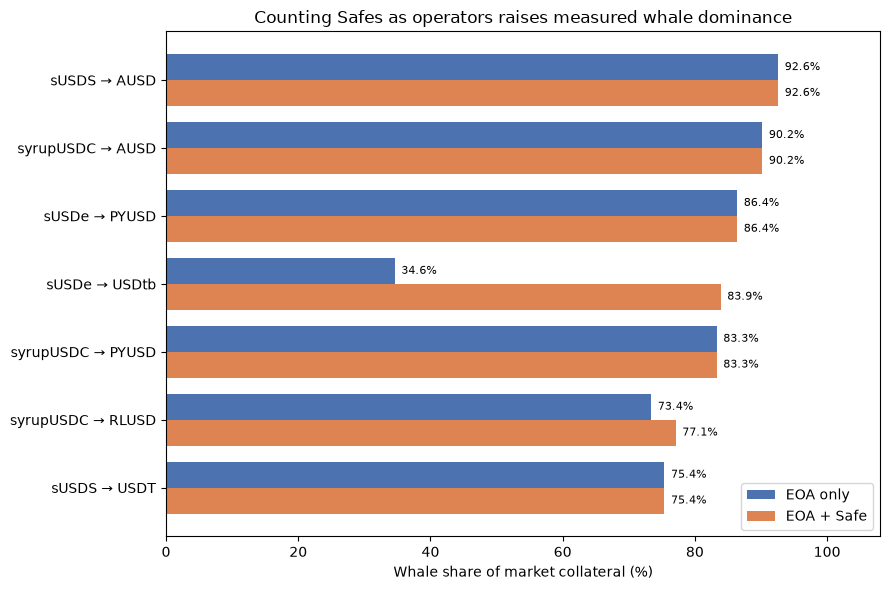

In [34]:
import matplotlib.pyplot as plt
import numpy as np

if comparison["delta"].abs().sum() == 0:
    print("All Morpho collateral wallets are EOAs; no Safe multisig operators were dropped,")
    print("so the EOA-only whale figures already hold for Morpho (EOA == EOA + Safe).")
else:
    n_whales_eoa = m_eoa["is_whale"].sum()
    n_whales_op = m_op["is_whale"].sum()
    share_eoa_total = 100 * m_eoa.loc[m_eoa["is_whale"], "collateral_value_usd"].sum() / m_eoa["collateral_value_usd"].sum()
    share_op_total = 100 * m_op.loc[m_op["is_whale"], "collateral_value_usd"].sum() / m_op["collateral_value_usd"].sum()

    print(f"Whale positions  EOA only: {int(n_whales_eoa)}   EOA + Safe: {int(n_whales_op)}")
    print(f"Whale collateral share  EOA only: {share_eoa_total:.1f}%   EOA + Safe: {share_op_total:.1f}%")

    plot = comparison[comparison["EOA + Safe"] > 0].sort_values("EOA + Safe").tail(12)
    y = np.arange(len(plot))
    h = 0.38

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(y + h/2, plot["EOA only"], height=h, color="#4C72B0", label="EOA only")
    ax.barh(y - h/2, plot["EOA + Safe"], height=h, color="#DD8452", label="EOA + Safe")
    ax.set_yticks(y)
    ax.set_yticklabels(plot.index)
    ax.set_xlabel("Whale share of market collateral (%)")
    ax.set_xlim(0, 108)
    ax.set_title("Counting Safes as operators raises measured whale dominance")
    for yi, a, b in zip(y, plot["EOA only"], plot["EOA + Safe"]):
        ax.text(a + 1, yi + h/2, f"{a:.1f}%", va="center", fontsize=8)
        ax.text(b + 1, yi - h/2, f"{b:.1f}%", va="center", fontsize=8)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

### Takeaway: EOA vs EOA + Safe

Once the collateral query scans the full Morpho markets rather than a pre-selected
EOA-only wallet list, the panel does contain multisig operators. The detector finds 25
Gnosis Safes among the Morpho collateral suppliers, three of them whales at the \$1M
threshold. Counting them lifts the overall whale collateral share from 77.3\% to 79.9\%,
and the effect is concentrated in a handful of markets, most sharply sUSDe to USDtb, where
a single Safe whale takes measured whale dominance from 34.6\% to 83.9\%. The earlier
impression that Morpho held no Safe operators was an artefact of the wallet filter on the
market-breakdown query, not a property of Morpho Blue.
